In [62]:
!pip install qiskit qiskit_aer
!pip install pylatexenc

# 1. **Basic Toffoli Gate**

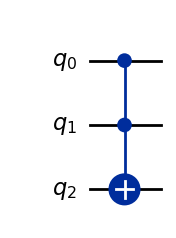

In [63]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(3)

# Toffoli: qubits 0 and 1 are controls, qubit 2 is the target
qc.ccx(0, 1, 2)

display(qc.draw('mpl'))

# 2. **Measurement**

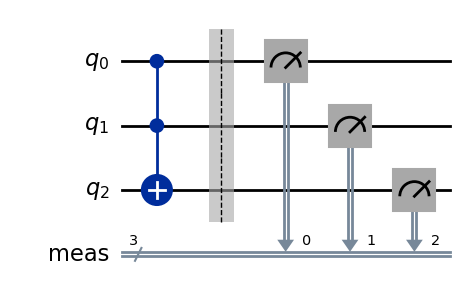

In [71]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Create 3 qubits and 3 classical bits
qc = QuantumCircuit(3)


# Apply Toffoli (CCNOT)
qc.ccx(0, 1, 2)

# Measure all qubits
qc.measure_all()

# Draw circuit
display(qc.draw('mpl'))

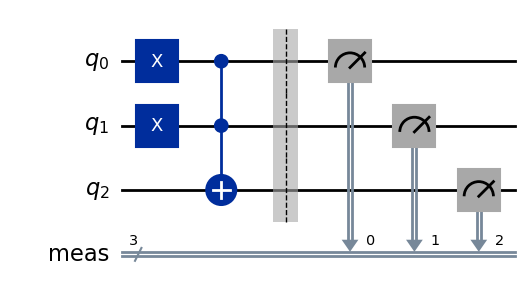

In [65]:
from qiskit_aer import AerSimulator

qc = QuantumCircuit(3)

# Prepare |110>
qc.x(0)
qc.x(1)

# Apply Toffoli
qc.ccx(0, 1, 2)

# Measure
qc.measure_all()

qc.draw('mpl')

# 3. **Read and Understand the Measurement**

{'111': 1024}


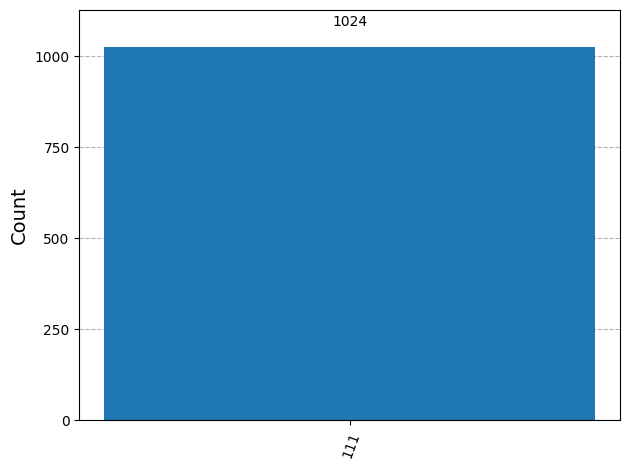

In [66]:
# Run simulation
simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()

# Get measurement results
counts = result.get_counts()
print(counts)

# Plot histogram
plot_histogram(counts)

---

# 4. **Bell State**

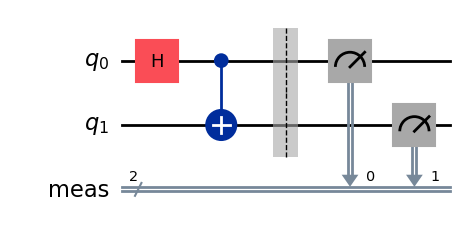

{'11': 511, '00': 513}


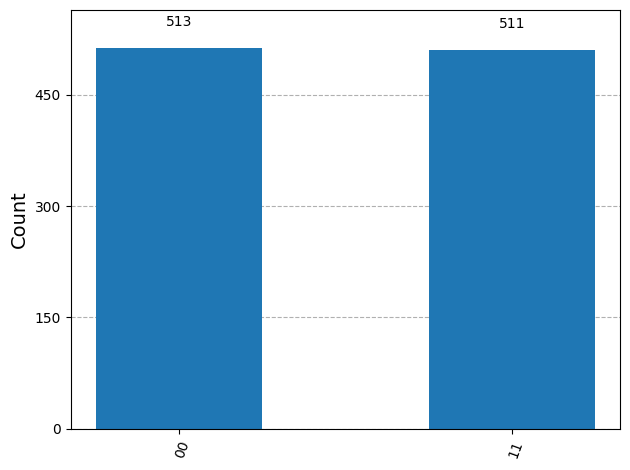

In [73]:
# Create 2 qubits and 2 classical bits
qc = QuantumCircuit(2)

# Create Bell state
qc.h(0)
qc.cx(0, 1)

# Measure
qc.measure_all()

# Draw circuit
display(qc.draw('mpl'))

# Run simulation
simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()

# Get results
counts = result.get_counts()
print(counts)

# Plot histogram
plot_histogram(counts)

---

# 4. **Product State**

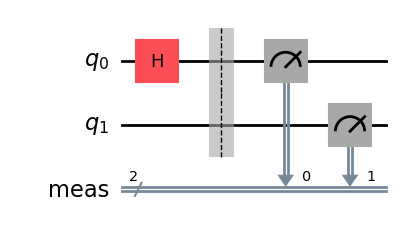

{'01': 524, '00': 500}


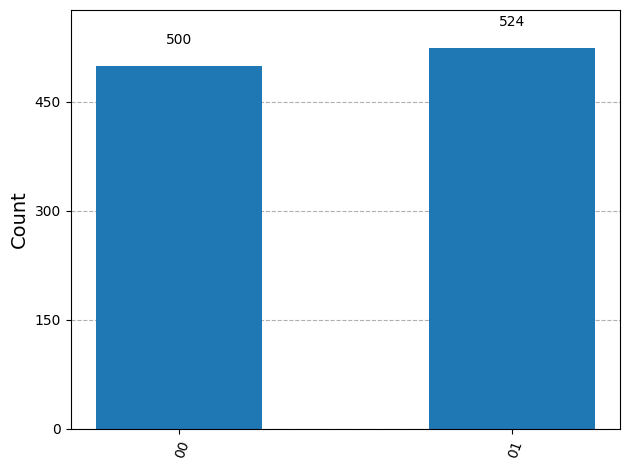

In [68]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

qc1 = QuantumCircuit(2)

qc1.h(0)

qc1.measure_all()

display(qc1.draw('mpl'))

simulator = AerSimulator()
result = simulator.run(qc1, shots=1024).result()

counts1 = result.get_counts()
print(counts1)

plot_histogram(counts1)

# 5. **Entangled States**

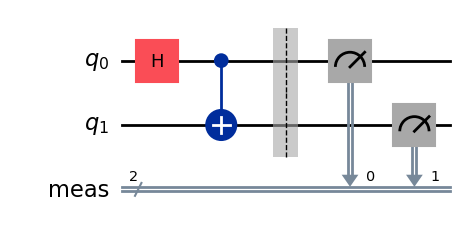

{'11': 522, '00': 502}


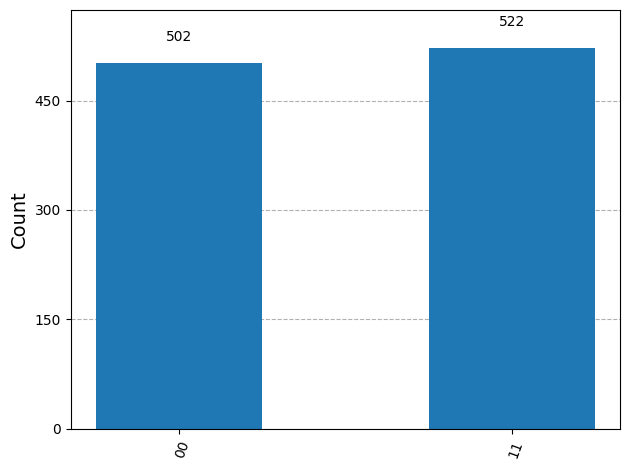

In [75]:
qc2 = QuantumCircuit(2)

qc2.h(0)
qc2.cx(0, 1)

qc2.measure_all()

display(qc2.draw('mpl'))

result = simulator.run(qc2, shots=1024).result()

counts2 = result.get_counts()
print(counts2)

plot_histogram(counts2)

---

# 6. **Measurement Basis**

## **Z-Basis and X-Basis Measurements**

Z-basis: {'11': 481, '00': 543}
X-basis: {'00': 502, '11': 522}


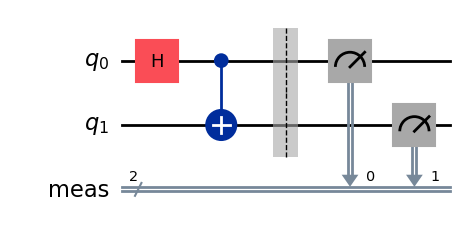

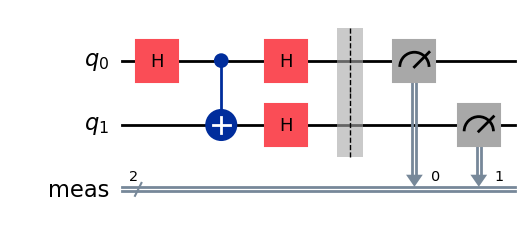

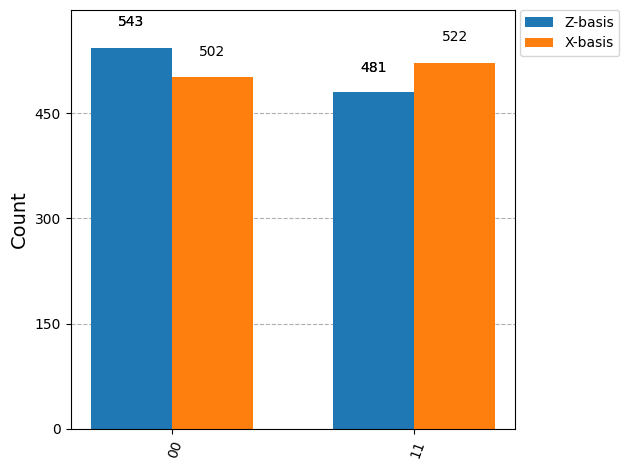

In [76]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

simulator = AerSimulator()

# -------------------------
# Z-basis measurement
# -------------------------
qc_z = QuantumCircuit(2)

qc_z.h(0)
qc_z.cx(0, 1)

qc_z.measure_all()

# -------------------------
# X-basis measurement
# -------------------------
qc_x = QuantumCircuit(2)

qc_x.h(0)
qc_x.cx(0, 1)

# Change measurement basis
qc_x.h(0)
qc_x.h(1)

qc_x.measure_all()

# Run simulations
result_z = simulator.run(qc_z, shots=1024).result()
result_x = simulator.run(qc_x, shots=1024).result()

counts_z = result_z.get_counts()
counts_x = result_x.get_counts()

print("Z-basis:", counts_z)
print("X-basis:", counts_x)

# Show circuits
display(qc_z.draw('mpl'))
display(qc_x.draw('mpl'))

# Compare histograms
plot_histogram(
    [counts_z, counts_x],
    legend=['Z-basis', 'X-basis']
)